# COMP9517 Lab 3 — BloodMNIST classification

Compare K-nearest neighbours (KNN), decision tree (DT), and stochastic gradient descent (SGD) on balanced subsets and the full official training/testing splits. All results below are generated by executing this notebook. The validation split is described but is not used for fitting or evaluation.

The images are RGB: flattening preserves all three channels (28 × 28 × 3 = 2,352 features). Raw pixel values are used, without tuning or scaling, to follow the specified default-parameter baseline. SGD can be sensitive to this feature scale. A fixed NumPy seed before each fit controls randomness without changing estimator parameters.

In [1]:
from pathlib import Path
import platform
import time
import warnings
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import sklearn
from IPython.display import display, Markdown
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import SGDClassifier
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, confusion_matrix, ConfusionMatrixDisplay)

SEED = 9517
LABELS = np.arange(8)
# Numeric IDs are taken directly from the supplied archive; no external label mapping is needed.
CLASS_NAMES = [f"Class {i}" for i in LABELS]
print({"Python": platform.python_version(), "OpenCV": cv2.__version__,
       "NumPy": np.__version__, "scikit-learn": sklearn.__version__})


{'Python': '3.13.2', 'OpenCV': '4.13.0', 'NumPy': '2.2.6', 'scikit-learn': '1.7.0'}


## 1. Inspect the supplied dataset

train: (11959, 28, 28, 3), labels: (11959,), dtype: uint8
val: (1712, 28, 28, 3), labels: (1712,), dtype: uint8
test: (3421, 28, 28, 3), labels: (3421,), dtype: uint8


,train,val,test,total
Class 0,852,122,244,1218
Class 1,2181,312,624,3117
Class 2,1085,155,311,1551
Class 3,2026,290,579,2895
Class 4,849,122,243,1214
Class 5,993,143,284,1420
Class 6,2330,333,666,3329
Class 7,1643,235,470,2348


Total images: 17092


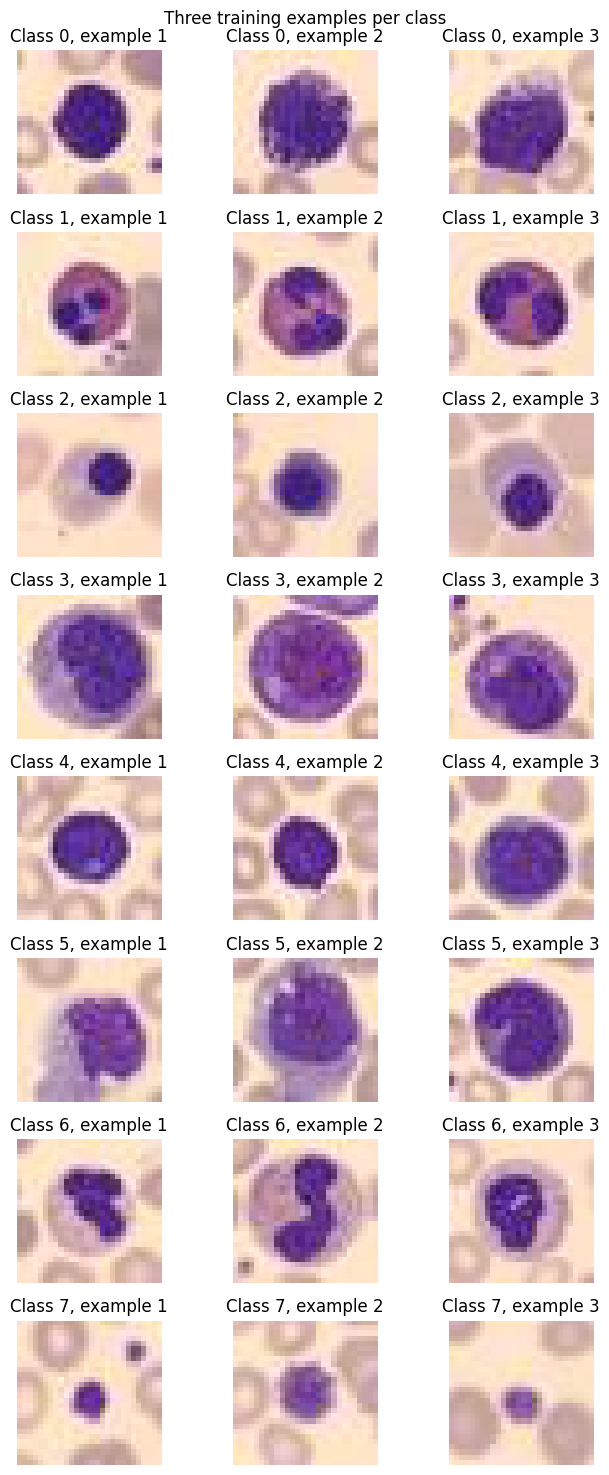

In [2]:
DATA_PATH = Path("BloodMNIST.npz")
with np.load(DATA_PATH, allow_pickle=False) as archive:
    data = {key: archive[key] for key in archive.files}
for split in ("train", "val", "test"):
    images, labels = data[f"{split}_images"], data[f"{split}_labels"].ravel()
    assert images.shape[1:] == (28, 28, 3)
    assert len(images) == len(labels)
    assert np.array_equal(np.unique(labels), LABELS)
    print(f"{split}: {images.shape}, labels: {labels.shape}, dtype: {images.dtype}")
counts = pd.DataFrame({s: np.bincount(data[f"{s}_labels"].ravel(), minlength=8)
                       for s in ("train", "val", "test")}, index=CLASS_NAMES)
counts["total"] = counts.sum(axis=1)
display(counts)
print("Total images:", int(counts["total"].sum()))
assert counts["total"].sum() == 17092

fig, axes = plt.subplots(8, 3, figsize=(7, 15))
for label in LABELS:
    indices = np.flatnonzero(data["train_labels"].ravel() == label)[:3]
    for column, index in enumerate(indices):
        # RGB is the archive's native order; imshow therefore needs no BGR conversion.
        axes[label, column].imshow(data["train_images"][index])
        axes[label, column].axis("off")
        axes[label, column].set_title(f"Class {label}, example {column + 1}")
fig.suptitle("Three training examples per class")
plt.tight_layout()
plt.show()


## 2. Balanced sampling and reshaping

Proportional stratification would preserve the original imbalance. The specification instead requests approximately equal class sizes, so sampling is random **within each class**, without replacement, with an equal quota. The official training and test arrays remain separate. The full experiment retains the original imbalance. No validation or test samples are added to training.

In [3]:
def balanced_indices(labels, size, seed):
    labels = np.asarray(labels).ravel()
    classes = np.unique(labels)
    if size <= 0 or size % len(classes):
        raise ValueError("Sample size must be positive and divisible by the class count")
    quota = size // len(classes)
    rng = np.random.default_rng(seed)
    groups = [np.flatnonzero(labels == c) for c in classes]
    if any(len(group) < quota for group in groups):
        raise ValueError("Insufficient samples for sampling without replacement")
    indices = np.concatenate([rng.choice(group, quota, replace=False) for group in groups])
    rng.shuffle(indices)
    return indices

train_y = data["train_labels"].ravel()
test_y = data["test_labels"].ravel()
train_idx = balanced_indices(train_y, 5000, SEED)
test_idx = balanced_indices(test_y, 1000, SEED + 1)
assert len(np.unique(train_idx)) == 5000
assert len(np.unique(test_idx)) == 1000
assert np.array_equal(train_idx, balanced_indices(train_y, 5000, SEED))
assert np.all(np.bincount(train_y[train_idx], minlength=8) == 625)
assert np.all(np.bincount(test_y[test_idx], minlength=8) == 125)

def flatten(images):
    return images.reshape(len(images), -1)

full_train_x = flatten(data["train_images"])
full_test_x = flatten(data["test_images"])
experiments = {
    "Balanced subset": (full_train_x[train_idx], train_y[train_idx], full_test_x[test_idx], test_y[test_idx]),
    "Full dataset": (full_train_x, train_y, full_test_x, test_y),
}
display(pd.DataFrame({"subset train": np.bincount(train_y[train_idx], minlength=8),
                      "subset test": np.bincount(test_y[test_idx], minlength=8),
                      "full train": np.bincount(train_y, minlength=8),
                      "full test": np.bincount(test_y, minlength=8)}, index=CLASS_NAMES))
for name, (xtr, ytr, xte, yte) in experiments.items():
    assert xtr.shape == (len(ytr), 2352)
    assert xte.shape == (len(yte), 2352)
    print(name, "training:", xtr.shape, "testing:", xte.shape)
print("Sampling, balance, uniqueness, reproducibility and reshape checks passed.")


,subset train,subset test,full train,full test
Class 0,625,125,852,244
Class 1,625,125,2181,624
Class 2,625,125,1085,311
Class 3,625,125,2026,579
Class 4,625,125,849,243
Class 5,625,125,993,284
Class 6,625,125,2330,666
Class 7,625,125,1643,470


Balanced subset training: (5000, 2352) testing: (1000, 2352)
Full dataset training: (11959, 2352) testing: (3421, 2352)
Sampling, balance, uniqueness, reproducibility and reshape checks passed.


## 3. Fit and evaluate all six configurations

KNN uses `n_neighbors=3`; SGD uses `max_iter=250`; DT uses all defaults. In particular, SGD retains its default convergence tolerance, so 250 is an upper bound and early stopping by convergence is possible. Each experiment creates fresh estimators. Accuracy, macro and weighted precision/recall/F1, per-class reports and confusion matrices are shown. Macro averages weight each class equally; weighted averages weight by test support. Rows in each confusion matrix are true classes and columns are predictions.

### Balanced subset — KNN

              precision    recall  f1-score   support

     Class 0     0.4913    0.6800    0.5705       125
     Class 1     0.6639    0.6480    0.6559       125
     Class 2     0.7007    0.7680    0.7328       125
     Class 3     0.5165    0.3760    0.4352       125
     Class 4     0.7969    0.8160    0.8063       125
     Class 5     0.5890    0.6880    0.6347       125
     Class 6     0.9155    0.5200    0.6633       125
     Class 7     0.9470    1.0000    0.9728       125

    accuracy                         0.6870      1000
   macro avg     0.7026    0.6870    0.6839      1000
weighted avg     0.7026    0.6870    0.6839      1000

Fit: 0.001s; predict: 0.131s
Training warnings: None


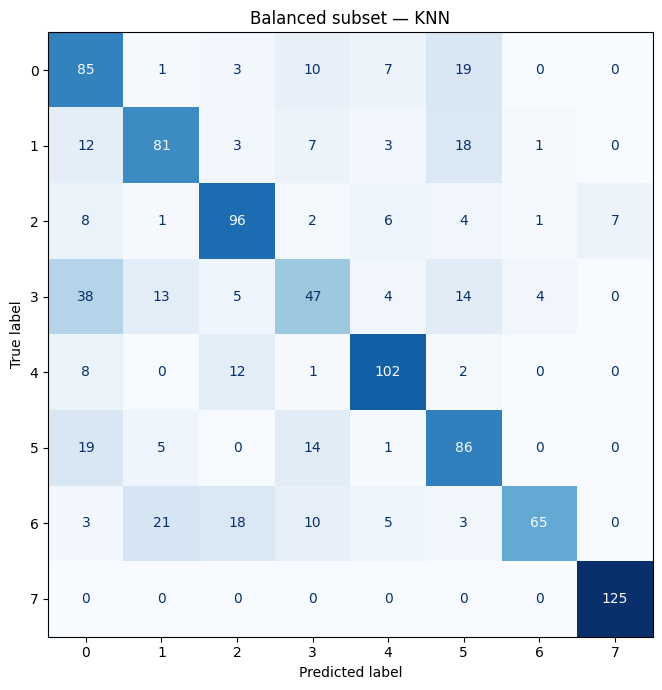

### Balanced subset — DT

              precision    recall  f1-score   support

     Class 0     0.5169    0.4880    0.5021       125
     Class 1     0.6796    0.5600    0.6140       125
     Class 2     0.7130    0.6560    0.6833       125
     Class 3     0.3401    0.4000    0.3676       125
     Class 4     0.6643    0.7600    0.7090       125
     Class 5     0.4308    0.4480    0.4392       125
     Class 6     0.6667    0.6720    0.6693       125
     Class 7     0.9746    0.9200    0.9465       125

    accuracy                         0.6130      1000
   macro avg     0.6233    0.6130    0.6164      1000
weighted avg     0.6233    0.6130    0.6164      1000

Fit: 6.802s; predict: 0.004s
Training warnings: None


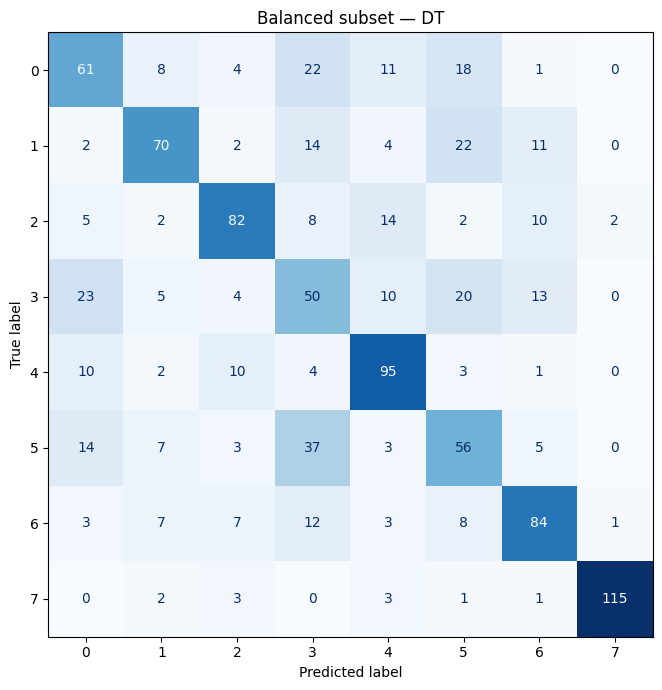

### Balanced subset — SGD

              precision    recall  f1-score   support

     Class 0     0.7750    0.2480    0.3758       125
     Class 1     0.6173    0.9680    0.7539       125
     Class 2     0.9688    0.4960    0.6561       125
     Class 3     0.4107    0.3680    0.3882       125
     Class 4     0.8762    0.7360    0.8000       125
     Class 5     0.6738    0.7600    0.7143       125
     Class 6     0.4378    0.7600    0.5556       125
     Class 7     0.9760    0.9760    0.9760       125

    accuracy                         0.6640      1000
   macro avg     0.7169    0.6640    0.6525      1000
weighted avg     0.7169    0.6640    0.6525      1000

Fit: 6.374s; predict: 0.007s
SGD actual epochs: 123
Training warnings: None


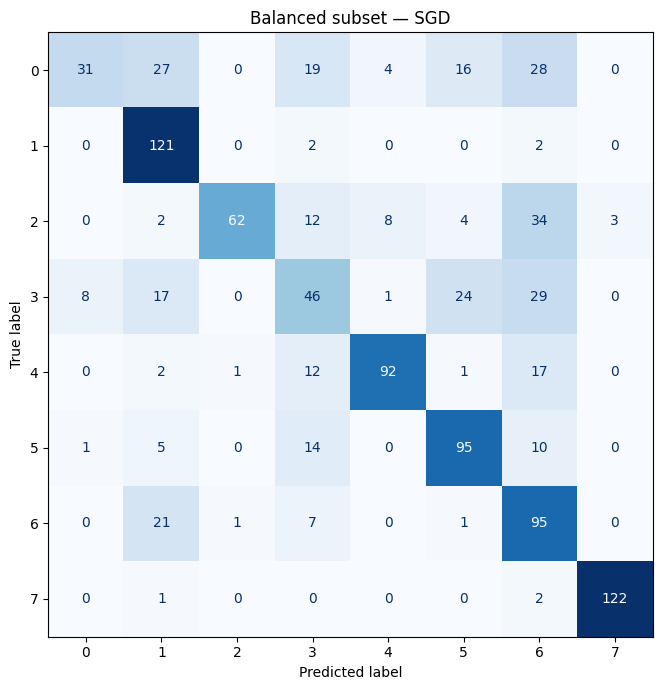

### Full dataset — KNN

              precision    recall  f1-score   support

     Class 0     0.4543    0.6311    0.5283       244
     Class 1     0.7223    0.8253    0.7704       624
     Class 2     0.6431    0.7588    0.6962       311
     Class 3     0.5782    0.5492    0.5633       579
     Class 4     0.7632    0.7160    0.7389       243
     Class 5     0.5617    0.6092    0.5845       284
     Class 6     0.9579    0.6156    0.7495       666
     Class 7     0.9549    0.9915    0.9729       470

    accuracy                         0.7150      3421
   macro avg     0.7044    0.7121    0.7005      3421
weighted avg     0.7390    0.7150    0.7174      3421

Fit: 0.001s; predict: 0.681s
Training warnings: None


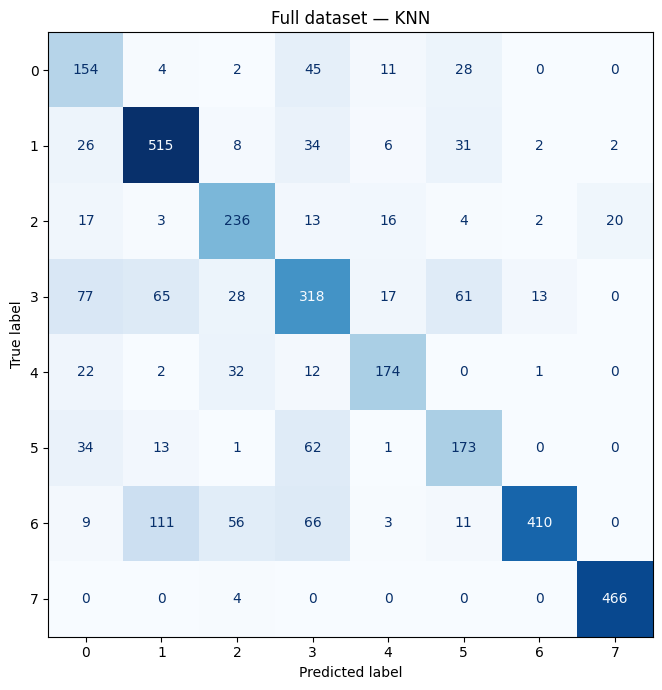

### Full dataset — DT

              precision    recall  f1-score   support

     Class 0     0.3684    0.4016    0.3843       244
     Class 1     0.7422    0.7244    0.7332       624
     Class 2     0.6613    0.6592    0.6602       311
     Class 3     0.4949    0.5009    0.4979       579
     Class 4     0.6360    0.5967    0.6157       243
     Class 5     0.3971    0.3803    0.3885       284
     Class 6     0.7151    0.7237    0.7194       666
     Class 7     0.9433    0.9553    0.9493       470

    accuracy                         0.6516      3421
   macro avg     0.6198    0.6178    0.6186      3421
weighted avg     0.6525    0.6516    0.6519      3421

Fit: 18.455s; predict: 0.011s
Training warnings: None


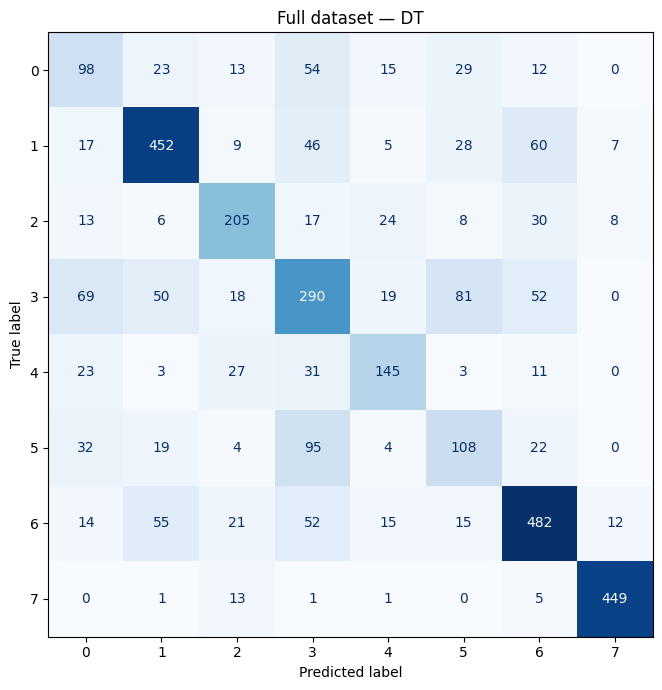

### Full dataset — SGD

              precision    recall  f1-score   support

     Class 0     0.6944    0.4098    0.5155       244
     Class 1     0.9369    0.8093    0.8684       624
     Class 2     0.9333    0.6302    0.7524       311
     Class 3     0.6417    0.2815    0.3914       579
     Class 4     0.9375    0.6790    0.7876       243
     Class 5     0.7056    0.4472    0.5474       284
     Class 6     0.4651    0.9820    0.6313       666
     Class 7     0.9180    1.0000    0.9572       470

    accuracy                         0.6957      3421
   macro avg     0.7791    0.6549    0.6814      3421
weighted avg     0.7557    0.6957    0.6856      3421

Fit: 18.247s; predict: 0.014s
SGD actual epochs: 182
Training warnings: None


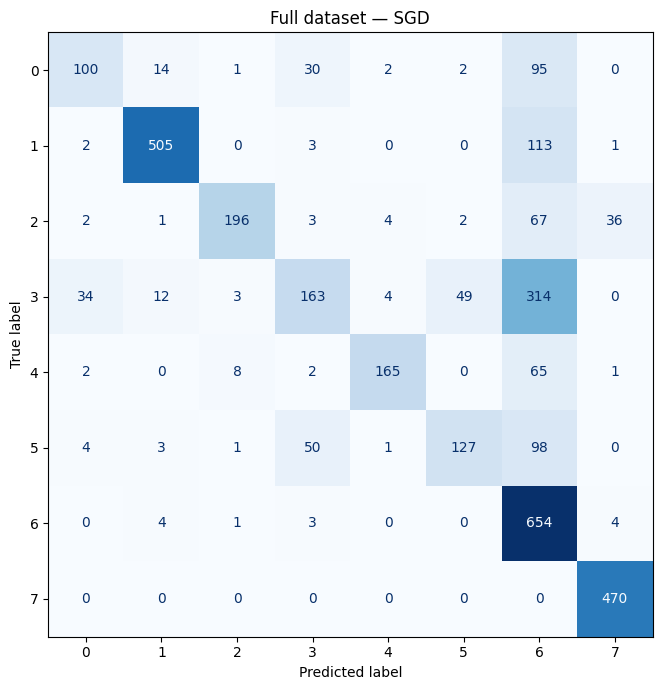

accuracy  fit_seconds  predict_seconds  \
experiment      classifier                                           
Balanced subset KNN           0.6870       0.0007           0.1305   
                DT            0.6130       6.8016           0.0045   
                SGD           0.6640       6.3739           0.0066   
Full dataset    KNN           0.7150       0.0009           0.6808   
                DT            0.6516      18.4550           0.0107   
                SGD           0.6957      18.2474           0.0137   

                            macro_precision  macro_recall  macro_f1  \
experiment      classifier                                            
Balanced subset KNN                  0.7026        0.6870    0.6839   
                DT                   0.6233        0.6130    0.6164   
                SGD                  0.7169        0.6640    0.6525   
Full dataset    KNN                  0.7044        0.7121    0.7005   
                DT                   0.6198        0.6178    0.6186   
                SGD                  0.7791        0.6549    0.6814   

                            weighted_precision  weighted_recall  weighted_f1  
experiment      classifier                                                    
Balanced subset KNN                     0.7026           0.6870       0.6839  
                DT                      0.6233           0.6130       0.6164  
                SGD                     0.7169           0.6640       0.6525  
Full dataset    KNN                     0.7390           0.7150       0.7174  
                DT                      0.6525           0.6516       0.6519  
                SGD                     0.7557           0.6957       0.6856

All six evaluations and confusion-matrix consistency checks passed.


In [4]:
def make_classifiers():
    return {"KNN": KNeighborsClassifier(n_neighbors=3),
            "DT": DecisionTreeClassifier(),
            "SGD": SGDClassifier(max_iter=250)}

records = []
evaluation = {}
for experiment, (xtr, ytr, xte, yte) in experiments.items():
    for name, model in make_classifiers().items():
        np.random.seed(SEED)
        start = time.perf_counter()
        with warnings.catch_warnings(record=True) as caught:
            warnings.simplefilter("always")
            model.fit(xtr, ytr)
        fit_seconds = time.perf_counter() - start
        start = time.perf_counter()
        pred = model.predict(xte)
        predict_seconds = time.perf_counter() - start
        record = {"experiment": experiment, "classifier": name,
                  "accuracy": accuracy_score(yte, pred),
                  "fit_seconds": fit_seconds, "predict_seconds": predict_seconds}
        for average in ("macro", "weighted"):
            p, r, f, _ = precision_recall_fscore_support(yte, pred, labels=LABELS,
                                                       average=average, zero_division=0)
            record.update({f"{average}_precision": p, f"{average}_recall": r, f"{average}_f1": f})
        records.append(record)
        cm = confusion_matrix(yte, pred, labels=LABELS)
        assert cm.shape == (8, 8) and cm.sum() == len(yte)
        assert np.array_equal(cm.sum(axis=1), np.bincount(yte, minlength=8))
        assert np.isclose(np.trace(cm) / cm.sum(), record["accuracy"])
        evaluation[(experiment, name)] = {"confusion_matrix": cm, "predictions": pred}
        display(Markdown(f"### {experiment} — {name}"))
        print(classification_report(yte, pred, labels=LABELS, target_names=CLASS_NAMES,
                                    digits=4, zero_division=0))
        print(f"Fit: {fit_seconds:.3f}s; predict: {predict_seconds:.3f}s")
        if hasattr(model, "n_iter_"):
            print("SGD actual epochs:", model.n_iter_)
        print("Training warnings:", [str(w.message) for w in caught] or "None")
        fig, ax = plt.subplots(figsize=(8, 7))
        ConfusionMatrixDisplay(cm, display_labels=LABELS).plot(ax=ax, colorbar=False, cmap="Blues")
        ax.set_title(f"{experiment} — {name}")
        plt.tight_layout()
        plt.show()

results = pd.DataFrame(records)
display(results.set_index(["experiment", "classifier"]).round(4))
assert len(results) == 6
metric_columns = [c for c in results if c in ("accuracy",) or c.startswith(("macro_", "weighted_"))]
assert np.isfinite(results[metric_columns].to_numpy()).all()
assert results[metric_columns].ge(0).all().all() and results[metric_columns].le(1).all().all()
print("All six evaluations and confusion-matrix consistency checks passed.")


## 4. Compare and discuss the observed results

In [5]:
comparison = results.pivot(index="classifier", columns="experiment", values=["accuracy", "macro_f1"])
display(comparison.round(4))
for name in ("KNN", "DT", "SGD"):
    small = results[(results.experiment == "Balanced subset") & (results.classifier == name)].iloc[0]
    full = results[(results.experiment == "Full dataset") & (results.classifier == name)].iloc[0]
    display(Markdown(f"- **{name}:** accuracy {small.accuracy:.4f} → {full.accuracy:.4f} "
                     f"({(full.accuracy-small.accuracy)*100:+.2f} percentage points); "
                     f"macro F1 {small.macro_f1:.4f} → {full.macro_f1:.4f}."))
for experiment in experiments:
    block = results[results.experiment == experiment]
    best = block.loc[block.accuracy.idxmax()]
    display(Markdown(f"**{experiment}:** {best.classifier} has the highest observed accuracy ({best.accuracy:.4f})."))
    for name in ("KNN", "DT", "SGD"):
        cm = evaluation[(experiment, name)]["confusion_matrix"].copy()
        np.fill_diagonal(cm, 0)
        true, predicted = np.unravel_index(cm.argmax(), cm.shape)
        print(f"{experiment}, {name}: largest off-diagonal error: class {true} → {predicted}, {cm[true, predicted]} images")


accuracy                     macro_f1             
experiment Balanced subset Full dataset Balanced subset Full dataset
classifier                                                          
DT                   0.613       0.6516          0.6164       0.6186
KNN                  0.687       0.7150          0.6839       0.7005
SGD                  0.664       0.6957          0.6525       0.6814

- **KNN:** accuracy 0.6870 → 0.7150 (+2.80 percentage points); macro F1 0.6839 → 0.7005.

- **DT:** accuracy 0.6130 → 0.6516 (+3.86 percentage points); macro F1 0.6164 → 0.6186.

- **SGD:** accuracy 0.6640 → 0.6957 (+3.17 percentage points); macro F1 0.6525 → 0.6814.

**Balanced subset:** KNN has the highest observed accuracy (0.6870).

Balanced subset, KNN: largest off-diagonal error: class 3 → 0, 38 images
Balanced subset, DT: largest off-diagonal error: class 5 → 3, 37 images
Balanced subset, SGD: largest off-diagonal error: class 2 → 6, 34 images


**Full dataset:** KNN has the highest observed accuracy (0.7150).

Full dataset, KNN: largest off-diagonal error: class 6 → 1, 111 images
Full dataset, DT: largest off-diagonal error: class 5 → 3, 95 images
Full dataset, SGD: largest off-diagonal error: class 3 → 6, 314 images


The full-data experiment changes both the training size/class balance and the testing population. Consequently, any measured difference cannot be attributed solely to more training images. Macro F1 is particularly helpful when comparing the imbalanced full test set, whereas accuracy and weighted scores give more influence to common classes.

KNN compares raw RGB distances, which can be affected by colour and alignment and requires work at prediction time. A default decision tree can fit complex pixel-level splits and may overfit. Default SGD learns linear decision boundaries and is sensitive to unscaled pixels and convergence. These are explanations of model properties, not proof of the cause of a particular score difference. No hyperparameters were selected against test results, and a single fixed-seed run does not establish statistical significance. The confusion matrices above identify the actual class confusions for this run.

## Verification and submission

The notebook checks dataset dimensions/counts, balanced sampling without duplicate indices, deterministic sampling, feature dimensions, all six metric ranges, and confusion matrix totals/accuracy agreement. Training and evaluation use only their respective official split arrays. Run all cells from the Lab3 directory with `BloodMNIST.npz` beside the notebook. The delivered notebook retains all outputs for inspection without rerunning. Review the results and ensure that any course disclosure requirements are satisfied before submitting.